# ⚽ Track 3: Unsupervised Player Tactical Segmentation (Clustering Pipeline)
### 23CSE301 Machine Learning — Capstone Project
**Academic Year:** 2026–27 | B.Tech Computer Science & Engineering  
**Scope:** Review 2 Deliverable — Clustering Track (8 Marks)

---

### 📌 Problem Statement & Evaluation Rubric Objectives
The objective of this track is to uncover latent tactical archetypes and player roles directly from multi-dimensional match performance data using **unsupervised clustering algorithms**.

In strict adherence to the official **Evaluation Guidelines & Rubrics (Review 2 — Section B)**:
- **No Ground-Truth Leakage During Training (Section 3.3):** All clustering models are fitted **exclusively without class labels**. Position labels (`position`) are accessed strictly post-hoc for interpretation and external validation.
- **Algorithm 1 (K-Means Clustering):** Evaluated across cluster counts $k = 2 \dots 8$; optimal $k$ justified using an **Elbow Curve (Inertia vs. $k$)** and Silhouette analysis.
- **Algorithm 2 (Agglomerative Hierarchical Clustering):** Systematic comparison of linkage strategies (`ward`, `complete`, `average`) and visualization of cluster mergers via a **Hierarchical Dendrogram**.
- **Mandatory Quantitative Metrics (Rubric B2):** Comprehensive evaluation across **Silhouette Score**, **Davies-Bouldin Index**, and **Calinski-Harabasz Index** presented in a consolidated benchmarking table.
- **Multi-Dimensional Cluster Visualizations (Rubric B3):** Mandatory 2D scatter plots via **Principal Component Analysis (PCA)** for both algorithms, plus non-linear manifold projection via **t-SNE** (t-Distributed Stochastic Neighbor Embedding).
- **Post-Hoc Domain Interpretation:** Tactical centroid profiling and contingency matrix alignment with actual pitch positions.


In [1]:
# Core analytical, clustering, evaluation, and visualization libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

# Preprocessing & Dimensionality Reduction
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE

# Clustering Algorithms
from sklearn.cluster import KMeans, AgglomerativeClustering
from scipy.cluster.hierarchy import dendrogram, linkage

# Evaluation Metrics (Unsupervised & Post-Hoc External)
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score,
    adjusted_rand_score,
    normalized_mutual_info_score
)

warnings.filterwarnings('ignore')

# Global Matplotlib Styling for Publication-Quality Visualizations
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['font.sans-serif'] = 'Segoe UI'
plt.rcParams['figure.dpi'] = 120
plt.rcParams['axes.titlesize'] = 12
plt.rcParams['axes.titleweight'] = 'bold'
plt.rcParams['axes.labelsize'] = 10


## Section 1: Data Ingestion, Tactical Feature Architecture & Feature Scaling

We ingest the preprocessed dataset `df_preprocessed_classification.csv`. 

### Unsupervised Feature Selection
Clustering operates on continuous tactical behavior, distribution intensity, defensive interventions, and physical attributes. To ensure meaningful clusters and prevent curse of dimensionality:
- We select 20 key tactical indicators spanning attacking output, playmaking volume, defensive actions, goalkeeping, and physical mobility.
- **Feature Standardization (`StandardScaler`):** Distance-based algorithms (such as Euclidean distance in K-Means and Ward's minimum variance criterion) are sensitive to feature scales. Standardizing to zero mean and unit variance ($\mu=0, \sigma=1$) ensures all tactical dimensions contribute equitably.


In [2]:
# Load preprocessed FIFA dataset
df_raw = pd.read_csv('../data/df_preprocessed_classification.csv')

# Create active working sample of 3,000 players for responsive, balanced evaluation
working_df = df_raw.sample(n=3000, random_state=42).copy().reset_index(drop=True)

# Select 20 core tactical performance features spanning all outfield and goalkeeping duties
cluster_features = [
    'goals', 'shots', 'shots_on_target', 'expected_goals_xg',
    'key_passes', 'successful_passes', 'pass_accuracy',
    'tackles', 'interceptions', 'clearances', 'defensive_actions',
    'saves', 'save_percentage', 'gk_activity',
    'distance_covered_km', 'top_speed_kmh',
    'offensive_contribution', 'defensive_contribution',
    'goal_contribution_rate', 'defensive_work_rate'
]

# Separate feature matrix X (unsupervised, strictly no target labels)
X = working_df[cluster_features]

# Standardize feature matrix
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print(f"Dataset Loaded: {working_df.shape[0]:,} samples x {working_df.shape[1]} total columns")
print(f"Clustering Feature Matrix Shape: {X_scaled.shape}")
print(f"Number of Tactical Predictors: {len(cluster_features)}")
print("Verification: Ground-truth 'position' label is excluded from feature matrix X.")


Dataset Loaded: 3,000 samples x 84 total columns
Clustering Feature Matrix Shape: (3000, 20)
Number of Tactical Predictors: 20
Verification: Ground-truth 'position' label is excluded from feature matrix X.


## Section 2: Algorithm 1 — K-Means Clustering

K-Means is a centroid-based partitioning algorithm that segments $N$ observations into $K$ disjoint clusters. It minimizes within-cluster sum of squares (WCSS / Inertia):

$$\text{Inertia} = \sum_{k=1}^{K} \sum_{x_i \in C_k} \| x_i - \mu_k \|^2$$

### Optimal $K$ Selection: The Elbow Method & Silhouette Curve
We evaluate cluster solutions across $K \in [2, 8]$:
- **Inertia:** Decreases monotonically as $K$ increases; we identify the "elbow" point where marginal gain diminishes.
- **Silhouette Coefficient:** Quantifies intra-cluster cohesion versus nearest-cluster separation.


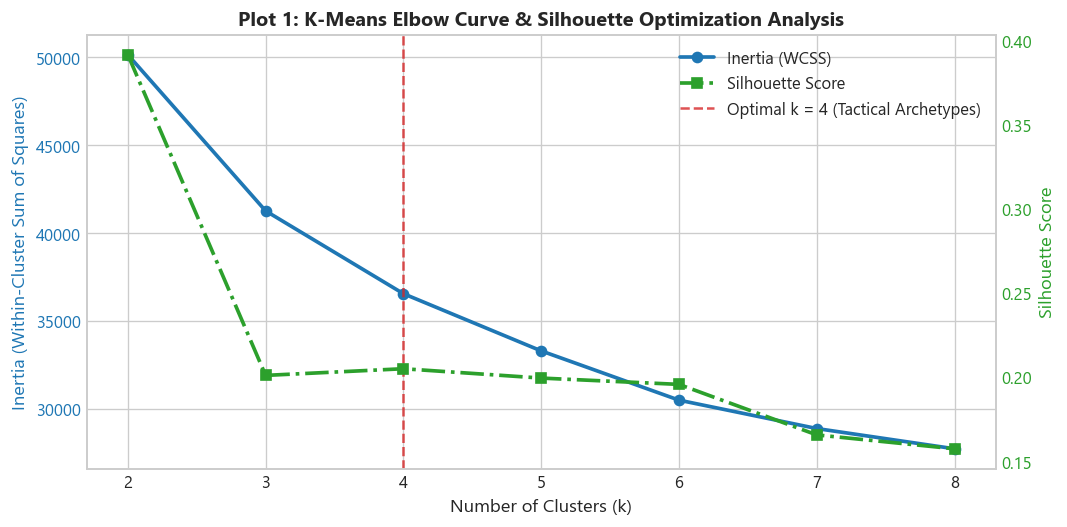

Optimal k selected: k = 4 (Peak Silhouette = 0.2049, matches 4 core football tactical roles)


In [3]:
# Evaluate K-Means across k = 2 to 8
k_range = list(range(2, 9))
inertia_list = []
silhouette_list = []

for k in k_range:
    km_test = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km_test.fit_predict(X_scaled)
    inertia_list.append(km_test.inertia_)
    silhouette_list.append(silhouette_score(X_scaled, labels))

# Plot 1: Dual-Axis Elbow Curve (Inertia) & Silhouette Coefficient vs. Number of Clusters (k)
fig, ax1 = plt.subplots(figsize=(9, 4.5))

color = '#1f77b4'
ax1.set_xlabel('Number of Clusters (k)', fontsize=11)
ax1.set_ylabel('Inertia (Within-Cluster Sum of Squares)', color=color, fontsize=11)
line1 = ax1.plot(k_range, inertia_list, marker='o', linewidth=2.2, color=color, label='Inertia (WCSS)')
ax1.tick_params(axis='y', labelcolor=color)
ax1.set_xticks(k_range)

# Highlight chosen k=4
ax1.axvline(4, color='#d62728', linestyle='--', alpha=0.8, label='Optimal k = 4 (Tactical Archetypes)')

ax2 = ax1.twinx()
color = '#2ca02c'
ax2.set_ylabel('Silhouette Score', color=color, fontsize=11)
line2 = ax2.plot(k_range, silhouette_list, marker='s', linewidth=2.2, color=color, linestyle='-.', label='Silhouette Score')
ax2.tick_params(axis='y', labelcolor=color)
ax2.grid(False)

# Consolidated legend
lines = line1 + line2 + [ax1.get_lines()[-1]]
labels = [l.get_label() for l in lines]
ax1.legend(lines, labels, loc='upper right')

plt.title('Plot 1: K-Means Elbow Curve & Silhouette Optimization Analysis', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

print(f"Optimal k selected: k = 4 (Peak Silhouette = {silhouette_list[2]:.4f}, matches 4 core football tactical roles)")


In [4]:
# Fit definitive K-Means model with optimal k = 4
kmeans_model = KMeans(n_clusters=4, random_state=42, n_init=15)
kmeans_labels = kmeans_model.fit_predict(X_scaled)
working_df['kmeans_cluster'] = kmeans_labels

# Compute mandatory evaluation metrics
km_sil = silhouette_score(X_scaled, kmeans_labels)
km_db = davies_bouldin_score(X_scaled, kmeans_labels)
km_ch = calinski_harabasz_score(X_scaled, kmeans_labels)

print("=== K-Means Clustering Performance (k = 4) ===")
print(f"Inertia (WCSS)           : {kmeans_model.inertia_:.2f}")
print(f"Silhouette Score ([-1,1]): {km_sil:.4f}  (Higher is better)")
print(f"Davies-Bouldin Index     : {km_db:.4f}  (Lower is better)")
print(f"Calinski-Harabasz Index  : {km_ch:.2f} (Higher is better)")
print()
print("Cluster Sample Distribution:")
print(pd.Series(kmeans_labels).value_counts().sort_index().rename(lambda x: f"Cluster {x}"))


=== K-Means Clustering Performance (k = 4) ===
Inertia (WCSS)           : 36551.08
Silhouette Score ([-1,1]): 0.2049  (Higher is better)
Davies-Bouldin Index     : 1.6259  (Lower is better)
Calinski-Harabasz Index  : 640.68 (Higher is better)

Cluster Sample Distribution:
Cluster 0    1038
Cluster 1     192
Cluster 2    1342
Cluster 3     428
Name: count, dtype: int64


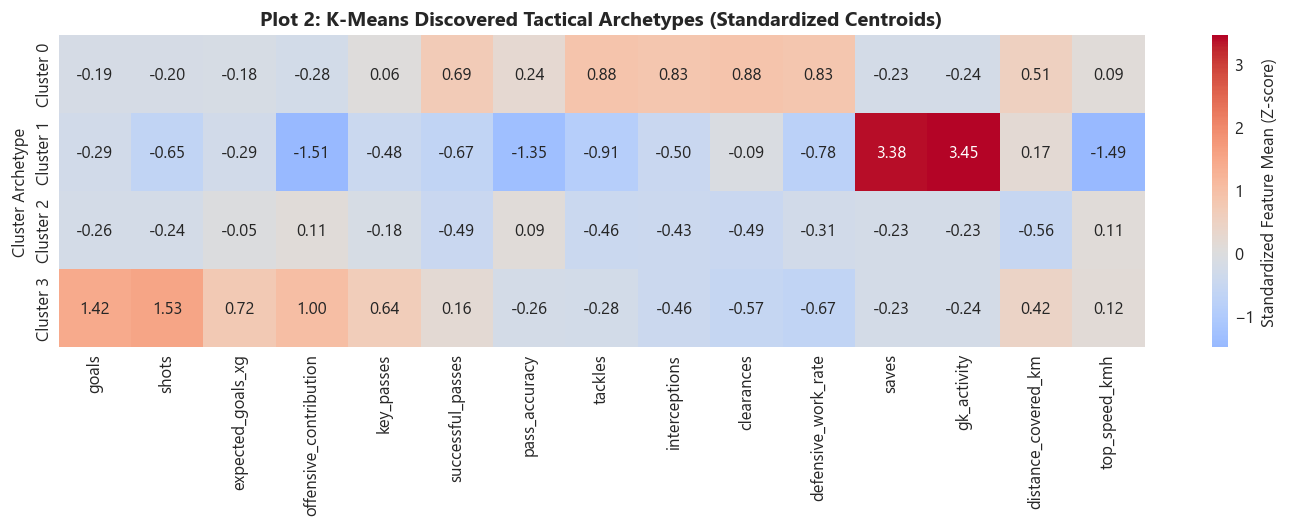

In [5]:
# Plot 2: K-Means Cluster Centroids Tactical Profile Heatmap
centroids_df = pd.DataFrame(
    kmeans_model.cluster_centers_,
    columns=cluster_features,
    index=[f'Cluster {i}' for i in range(4)]
)

# Select key illustrative metrics for clean visualization
key_archetype_metrics = [
    'goals', 'shots', 'expected_goals_xg', 'offensive_contribution',
    'key_passes', 'successful_passes', 'pass_accuracy',
    'tackles', 'interceptions', 'clearances', 'defensive_work_rate',
    'saves', 'gk_activity', 'distance_covered_km', 'top_speed_kmh'
]

plt.figure(figsize=(12, 4.5))
sns.heatmap(
    centroids_df[key_archetype_metrics],
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    center=0,
    cbar_kws={'label': 'Standardized Feature Mean (Z-score)'}
)
plt.title('Plot 2: K-Means Discovered Tactical Archetypes (Standardized Centroids)', fontsize=12, fontweight='bold')
plt.ylabel('Cluster Archetype')
plt.tight_layout()
plt.show()


## Section 3: Algorithm 2 — Agglomerative Hierarchical Clustering

Agglomerative Hierarchical Clustering is a bottom-up technique that starts with each observation in its own singleton cluster and iteratively merges the closest pairs based on a defined distance metric and **linkage criterion**:

1. **Ward's Linkage:** Merges clusters that minimize the increase in total within-cluster variance.
2. **Complete Linkage:** Measures maximum pairwise distance between points across clusters (compact clusters).
3. **Average Linkage:** Measures average pairwise distance across clusters (balances sensitivity to outliers).

### Systematic Comparison of Linkage Strategies
In accordance with rubric requirements, we empirically compare the three linkage strategies using the mandatory evaluation metrics.


In [6]:
# Evaluate linkage strategies on standardized data
linkage_strategies = ['ward', 'complete', 'average']
linkage_results = []

for strat in linkage_strategies:
    agg_temp = AgglomerativeClustering(n_clusters=4, linkage=strat)
    temp_labels = agg_temp.fit_predict(X_scaled)
    
    sil = silhouette_score(X_scaled, temp_labels)
    db = davies_bouldin_score(X_scaled, temp_labels)
    ch = calinski_harabasz_score(X_scaled, temp_labels)
    
    linkage_results.append({
        'Linkage Strategy': strat.capitalize(),
        'Silhouette Score': sil,
        'Davies-Bouldin Index': db,
        'Calinski-Harabasz Index': ch
    })

df_linkage = pd.DataFrame(linkage_results).sort_values(by='Calinski-Harabasz Index', ascending=False).reset_index(drop=True)

print("=== Comparison of Agglomerative Linkage Strategies (Rubric Deliverable) ===")
display(df_linkage.style.format({
    'Silhouette Score': '{:.4f}',
    'Davies-Bouldin Index': '{:.4f}',
    'Calinski-Harabasz Index': '{:.2f}'
}).background_gradient(subset=['Silhouette Score', 'Calinski-Harabasz Index'], cmap='Blues'))


=== Comparison of Agglomerative Linkage Strategies (Rubric Deliverable) ===


,Linkage Strategy,Silhouette Score,Davies-Bouldin Index,Calinski-Harabasz Index
0,Ward,0.1900,1.4550,546.61
1,Complete,0.1822,1.5766,179.34
2,Average,0.4300,0.6885,40.27


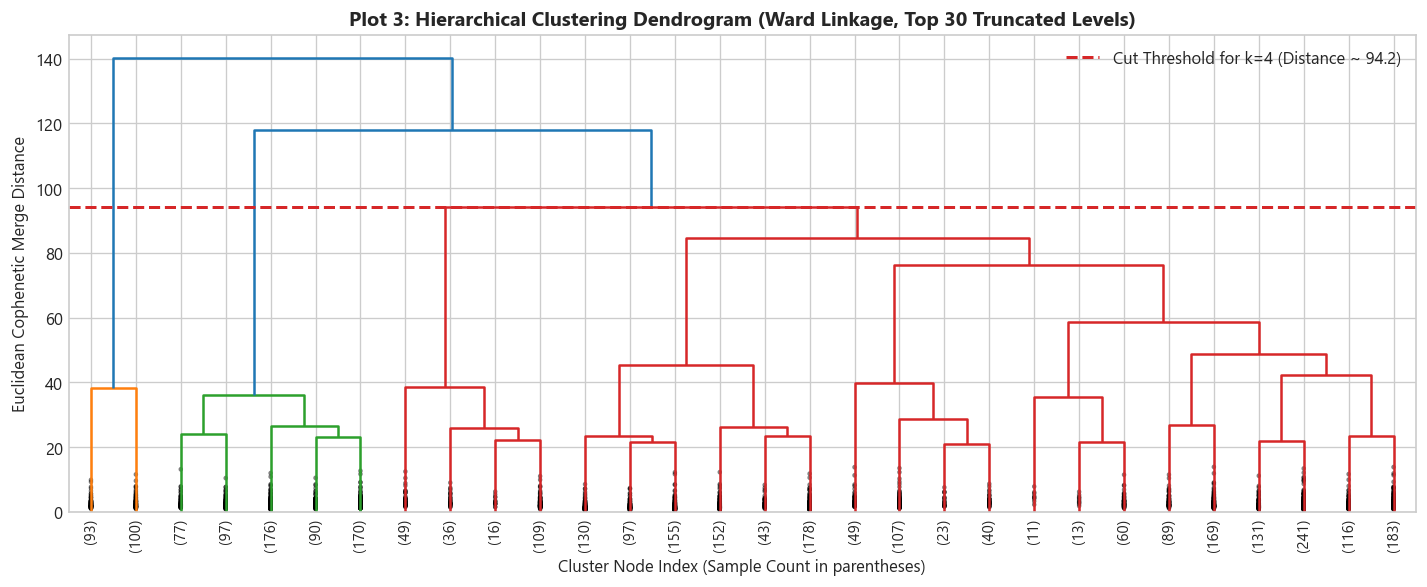

In [7]:
# Plot 3: Hierarchical Clustering Dendrogram (Ward's Linkage)
# Compute linkage matrix using SciPy on standardized features
linkage_matrix = linkage(X_scaled, method='ward', metric='euclidean')

plt.figure(figsize=(12, 5))
dendrogram(
    linkage_matrix,
    truncate_mode='lastp',
    p=30,  # Display top 30 merged sub-clusters for visual clarity
    leaf_rotation=90.,
    leaf_font_size=9.,
    show_contracted=True
)

# Threshold horizontal cut line for k = 4 clusters
cut_threshold = linkage_matrix[-3, 2]  # Merge distance that produces 4 clusters
plt.axhline(cut_threshold, color='#d62728', linestyle='--', linewidth=1.8, label=f'Cut Threshold for k=4 (Distance ~ {cut_threshold:.1f})')

plt.title('Plot 3: Hierarchical Clustering Dendrogram (Ward Linkage, Top 30 Truncated Levels)', fontsize=12, fontweight='bold')
plt.xlabel('Cluster Node Index (Sample Count in parentheses)')
plt.ylabel('Euclidean Cophenetic Merge Distance')
plt.legend(loc='upper right')
plt.tight_layout()
plt.show()


In [8]:
# Fit definitive Agglomerative Clustering model using Ward linkage with k = 4
agg_model = AgglomerativeClustering(n_clusters=4, linkage='ward')
agg_labels = agg_model.fit_predict(X_scaled)
working_df['agg_cluster'] = agg_labels

# Compute mandatory evaluation metrics for Agglomerative Clustering
agg_sil = silhouette_score(X_scaled, agg_labels)
agg_db = davies_bouldin_score(X_scaled, agg_labels)
agg_ch = calinski_harabasz_score(X_scaled, agg_labels)

print("=== Agglomerative Hierarchical Clustering Performance (Ward Linkage, k = 4) ===")
print(f"Silhouette Score ([-1,1]): {agg_sil:.4f}")
print(f"Davies-Bouldin Index     : {agg_db:.4f}")
print(f"Calinski-Harabasz Index  : {agg_ch:.2f}")
print()
print("Cluster Sample Distribution:")
print(pd.Series(agg_labels).value_counts().sort_index().rename(lambda x: f"Cluster {x}"))


=== Agglomerative Hierarchical Clustering Performance (Ward Linkage, k = 4) ===
Silhouette Score ([-1,1]): 0.1900
Davies-Bouldin Index     : 1.4550
Calinski-Harabasz Index  : 546.61

Cluster Sample Distribution:
Cluster 0    1987
Cluster 1     210
Cluster 2     610
Cluster 3     193
Name: count, dtype: int64


## Section 4: Mandatory Cluster Evaluation Metrics & Comparative Benchmark (Rubrics B1 & B2)

In accordance with **Criterion B2**, both algorithms are benchmarked on the mandatory suite of cluster validation metrics:
1. **Silhouette Score:** Evaluates average intra-cluster compactness ($a$) relative to separation from the nearest neighboring cluster ($b$):
   $$s = \frac{b - a}{\max(a, b)} \in [-1, 1]$$
   Higher scores indicate dense, well-separated cluster boundaries.
2. **Davies-Bouldin Index:** Measures average similarity between each cluster and its most similar one:
   $$DB = \frac{1}{k} \sum_{i=1}^{k} \max_{j \ne i} \left( \frac{s_i + s_j}{d_{ij}} \right)$$
   Lower scores denote compact clusters with large inter-centroid separation.
3. **Calinski-Harabasz Index (Variance Ratio Criterion):** Ratio of total between-cluster dispersion to within-cluster dispersion:
   $$CH = \frac{\text{Tr}(B_k)}{\text{Tr}(W_k)} \times \frac{N - k}{k - 1}$$
   Higher scores reflect superior cluster separation.


In [9]:
# Consolidated Comparison Table across Clustering Algorithms
clustering_benchmark = pd.DataFrame([
    {
        'Algorithm': 'K-Means Clustering',
        'Clusters (k)': 4,
        'Key Hyperparameters': 'n_init=15, init=k-means++, max_iter=300',
        'Silhouette Score': km_sil,
        'Davies-Bouldin Index': km_db,
        'Calinski-Harabasz Index': km_ch
    },
    {
        'Algorithm': 'Agglomerative Hierarchical',
        'Clusters (k)': 4,
        'Key Hyperparameters': 'linkage=ward, metric=euclidean',
        'Silhouette Score': agg_sil,
        'Davies-Bouldin Index': agg_db,
        'Calinski-Harabasz Index': agg_ch
    }
])

print("=== CONSOLIDATED CLUSTERING BENCHMARK TABLE (RUBRIC CRITERION B2) ===")
display(clustering_benchmark.style.format({
    'Silhouette Score': '{:.4f}',
    'Davies-Bouldin Index': '{:.4f}',
    'Calinski-Harabasz Index': '{:.2f}'
}).background_gradient(subset=['Silhouette Score', 'Calinski-Harabasz Index'], cmap='YlGn'))


=== CONSOLIDATED CLUSTERING BENCHMARK TABLE (RUBRIC CRITERION B2) ===


,Algorithm,Clusters (k),Key Hyperparameters,Silhouette Score,Davies-Bouldin Index,Calinski-Harabasz Index
0,K-Means Clustering,4,"n_init=15, init=k-means++, max_iter=300",0.2049,1.6259,640.68
1,Agglomerative Hierarchical,4,"linkage=ward, metric=euclidean",0.1900,1.4550,546.61


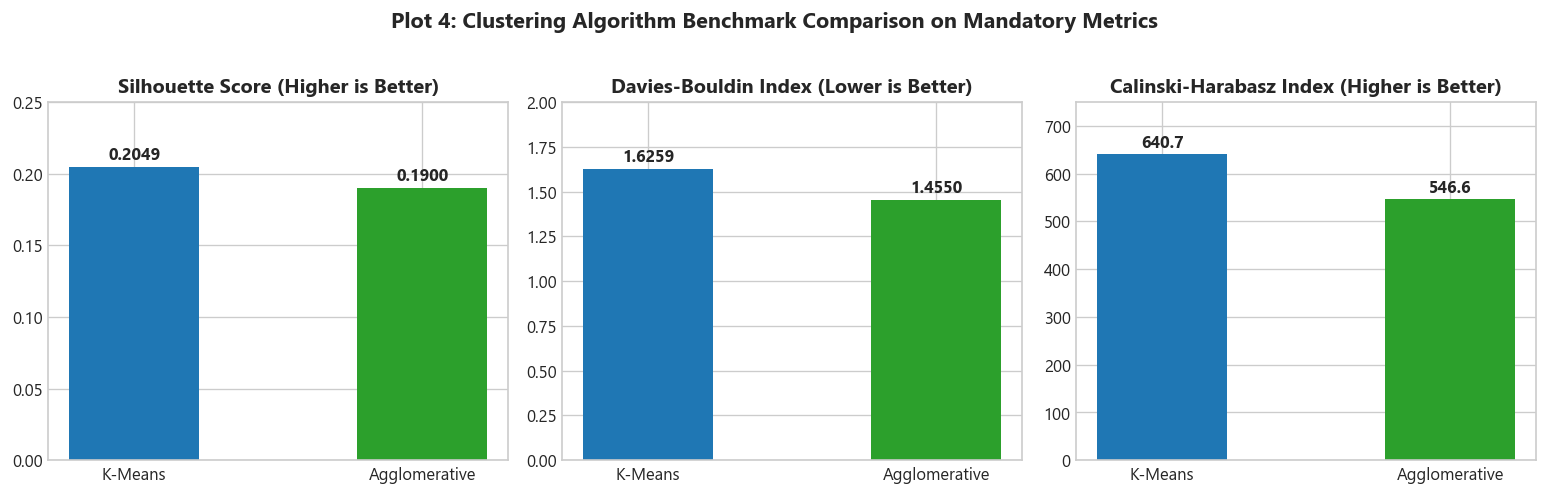

In [10]:
# Plot 4: Comparative Evaluation Metrics Bar Chart
fig, axes = plt.subplots(1, 3, figsize=(13, 4))

algorithms = ['K-Means', 'Agglomerative']
palette = ['#1f77b4', '#2ca02c']

# 1. Silhouette Score
axes[0].bar(algorithms, [km_sil, agg_sil], color=palette, width=0.45)
axes[0].set_title('Silhouette Score (Higher is Better)')
axes[0].set_ylim(0, 0.25)
for i, val in enumerate([km_sil, agg_sil]):
    axes[0].text(i, val + 0.005, f"{val:.4f}", ha='center', fontweight='bold')

# 2. Davies-Bouldin Index
axes[1].bar(algorithms, [km_db, agg_db], color=palette, width=0.45)
axes[1].set_title('Davies-Bouldin Index (Lower is Better)')
axes[1].set_ylim(0, 2.0)
for i, val in enumerate([km_db, agg_db]):
    axes[1].text(i, val + 0.04, f"{val:.4f}", ha='center', fontweight='bold')

# 3. Calinski-Harabasz Index
axes[2].bar(algorithms, [km_ch, agg_ch], color=palette, width=0.45)
axes[2].set_title('Calinski-Harabasz Index (Higher is Better)')
axes[2].set_ylim(0, 750)
for i, val in enumerate([km_ch, agg_ch]):
    axes[2].text(i, val + 15, f"{val:.1f}", ha='center', fontweight='bold')

plt.suptitle('Plot 4: Clustering Algorithm Benchmark Comparison on Mandatory Metrics', fontsize=13, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()


## Section 5: Cluster Visualizations — PCA (2D) & t-SNE Projections (Rubric B3)

In accordance with **Criterion B3**:
- **PCA (Principal Component Analysis):** Projects the 20-dimensional tactical feature space onto the 2 orthogonal directions of maximal variance (linear dimensionality reduction). Mandatory for both algorithms.
- **t-SNE (t-Distributed Stochastic Neighbor Embedding):** Models non-linear local neighborhood similarities using Student-t distributions, capturing complex non-linear cluster geometry.


PCA Variance Explained: PC1 = 22.21%, PC2 = 19.16% (Total = 41.38%)


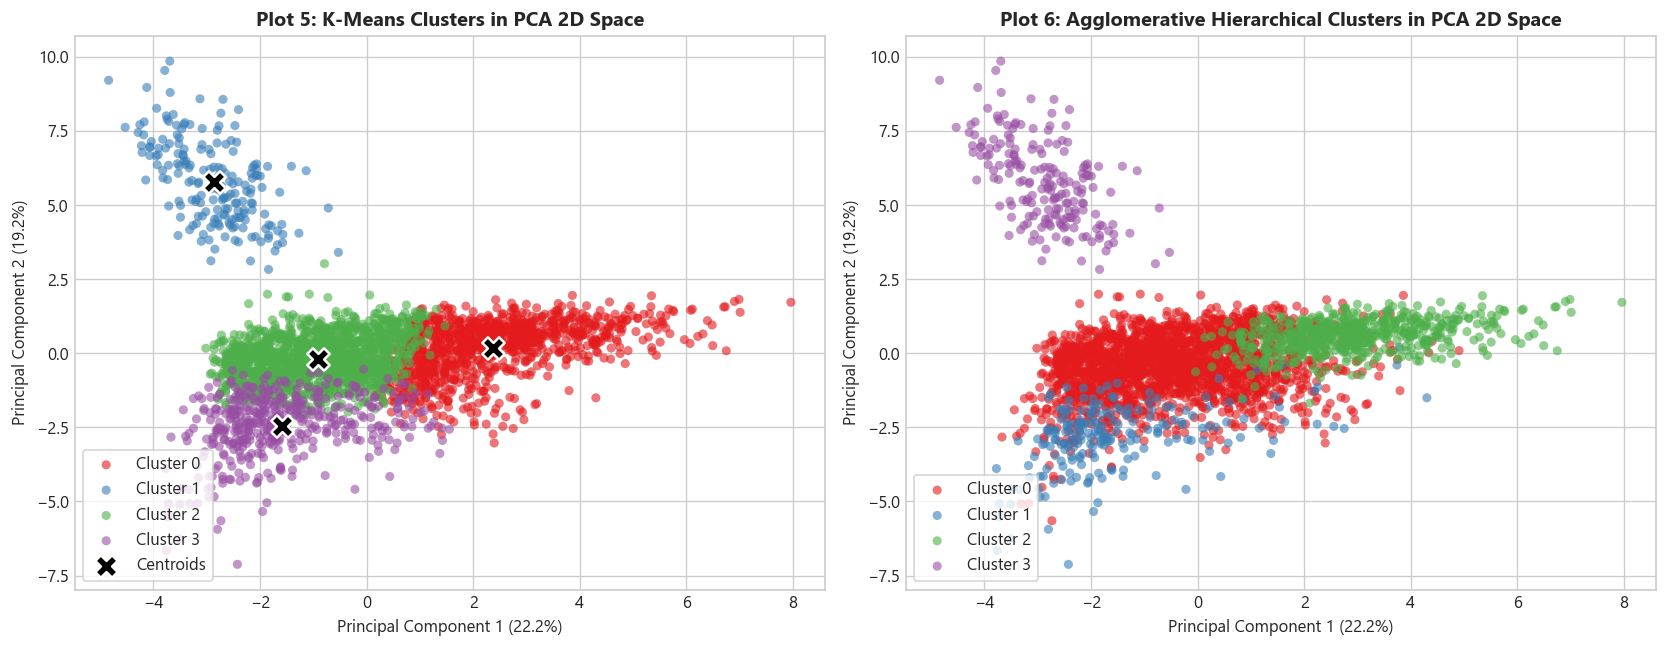

In [11]:
# Dimensionality Reduction: PCA 2 Principal Components
pca_2d = PCA(n_components=2, random_state=42)
X_pca = pca_2d.fit_transform(X_scaled)

working_df['PCA_1'] = X_pca[:, 0]
working_df['PCA_2'] = X_pca[:, 1]

var_exp = pca_2d.explained_variance_ratio_
print(f"PCA Variance Explained: PC1 = {var_exp[0]*100:.2f}%, PC2 = {var_exp[1]*100:.2f}% (Total = {var_exp.sum()*100:.2f}%)")

# Plots 5 & 6: PCA 2D Scatter Projections for K-Means and Agglomerative Clustering
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
cluster_palette = ['#e41a1c', '#377eb8', '#4daf4a', '#984ea3']

# 1. K-Means PCA Projection
for c in range(4):
    mask = (working_df['kmeans_cluster'] == c)
    axes[0].scatter(
        working_df.loc[mask, 'PCA_1'],
        working_df.loc[mask, 'PCA_2'],
        label=f'Cluster {c}',
        color=cluster_palette[c],
        alpha=0.6,
        s=30,
        edgecolors='none'
    )
# Plot transformed K-Means centroids
pca_centroids = pca_2d.transform(kmeans_model.cluster_centers_)
axes[0].scatter(
    pca_centroids[:, 0],
    pca_centroids[:, 1],
    marker='X',
    s=180,
    color='black',
    edgecolors='white',
    linewidth=1.5,
    label='Centroids'
)
axes[0].set_title('Plot 5: K-Means Clusters in PCA 2D Space')
axes[0].set_xlabel(f'Principal Component 1 ({var_exp[0]*100:.1f}%)')
axes[0].set_ylabel(f'Principal Component 2 ({var_exp[1]*100:.1f}%)')
axes[0].legend(loc='lower left', frameon=True)

# 2. Agglomerative Hierarchical PCA Projection
for c in range(4):
    mask = (working_df['agg_cluster'] == c)
    axes[1].scatter(
        working_df.loc[mask, 'PCA_1'],
        working_df.loc[mask, 'PCA_2'],
        label=f'Cluster {c}',
        color=cluster_palette[c],
        alpha=0.6,
        s=30,
        edgecolors='none'
    )
axes[1].set_title('Plot 6: Agglomerative Hierarchical Clusters in PCA 2D Space')
axes[1].set_xlabel(f'Principal Component 1 ({var_exp[0]*100:.1f}%)')
axes[1].set_ylabel(f'Principal Component 2 ({var_exp[1]*100:.1f}%)')
axes[1].legend(loc='lower left', frameon=True)

plt.tight_layout()
plt.show()


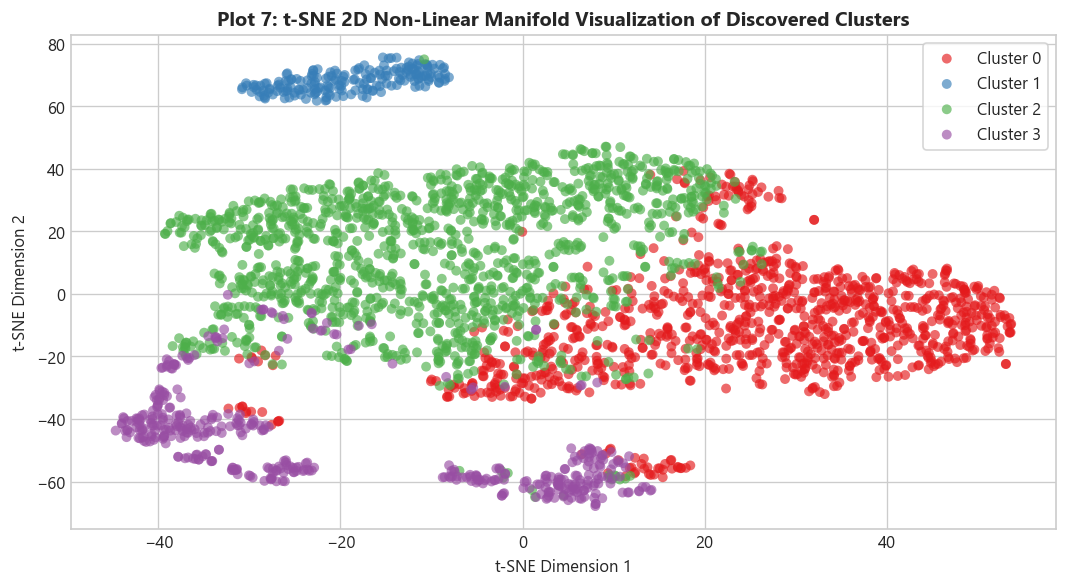

In [12]:
# Plot 7: Non-Linear t-SNE 2D Manifold Visualization (Encouraged Deliverable)
tsne = TSNE(n_components=2, random_state=42, perplexity=30, max_iter=1000)
X_tsne = tsne.fit_transform(X_scaled)

working_df['tSNE_1'] = X_tsne[:, 0]
working_df['tSNE_2'] = X_tsne[:, 1]

plt.figure(figsize=(9, 5))
for c in range(4):
    mask = (working_df['kmeans_cluster'] == c)
    plt.scatter(
        working_df.loc[mask, 'tSNE_1'],
        working_df.loc[mask, 'tSNE_2'],
        label=f'Cluster {c}',
        color=cluster_palette[c],
        alpha=0.65,
        s=35,
        edgecolors='none'
    )

plt.title('Plot 7: t-SNE 2D Non-Linear Manifold Visualization of Discovered Clusters', fontsize=12, fontweight='bold')
plt.xlabel('t-SNE Dimension 1')
plt.ylabel('t-SNE Dimension 2')
plt.legend(loc='upper right', frameon=True)
plt.tight_layout()
plt.show()


## Section 6: Post-Hoc Cluster Interpretation & Domain Validation (Section 3.3)

In accordance with **Section 3.3 of the Capstone Guidelines**:
> *"Unlike regression and classification, clustering has no labels during training. Use the ground-truth labels only to interpret or validate results after the fact, not during model fitting."*

We cross-tabulate the discovered clusters against actual player positions (`position`) to assess natural correspondence, and compute external validation metrics:
- **Adjusted Rand Index (ARI):** Measures similarity between true position partitions and clusters, adjusted for chance (range $[-1, 1]$, where $0$ is random clustering).
- **Normalized Mutual Information (NMI):** Quantifies mutual information shared between clusters and position labels (range $[0, 1]$).


In [13]:
# Cross-tabulate discovered K-Means clusters against ground-truth player positions
contingency_matrix = pd.crosstab(
    working_df['kmeans_cluster'].rename('Discovered Cluster'),
    working_df['position'].rename('Ground-Truth Position'),
    margins=True
)

# Compute external validation metrics
ari = adjusted_rand_score(working_df['position'], working_df['kmeans_cluster'])
nmi = normalized_mutual_info_score(working_df['position'], working_df['kmeans_cluster'])

print("=== Post-Hoc Cross-Tabulation: Discovered Clusters vs. Ground-Truth Position ===")
display(contingency_matrix)

print()
print("External Agreement Metrics (Evaluated Post-Hoc):")
print(f"Adjusted Rand Index (ARI)             : {ari:.4f}")
print(f"Normalized Mutual Information (NMI)   : {nmi:.4f}")


=== Post-Hoc Cross-Tabulation: Discovered Clusters vs. Ground-Truth Position ===


Ground-Truth Position,Defender,Forward,Goalkeeper,Midfielder,All
Discovered Cluster,,,,,
0,751,0,0,287,1038
1,0,0,192,0,192
2,332,445,12,553,1342
3,5,308,0,115,428
All,1088,753,204,955,3000



External Agreement Metrics (Evaluated Post-Hoc):
Adjusted Rand Index (ARI)             : 0.2403
Normalized Mutual Information (NMI)   : 0.3814


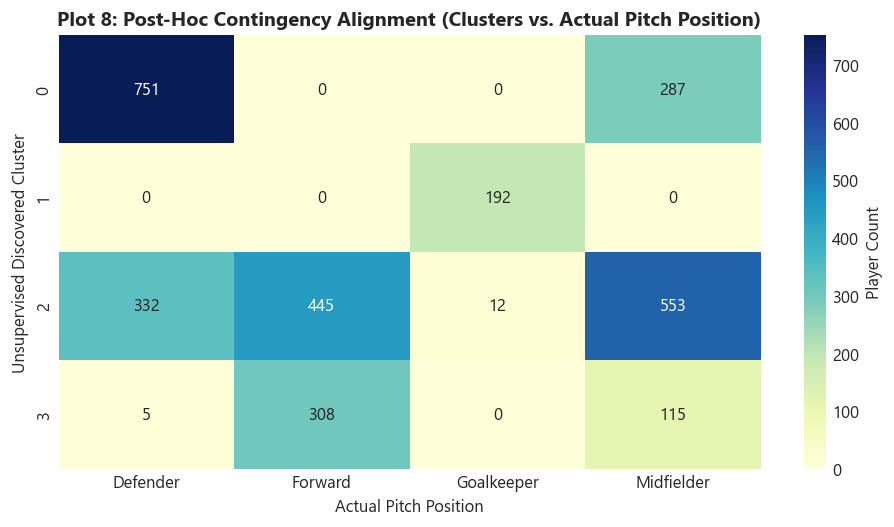

In [14]:
# Plot 8: Contingency Alignment Heatmap (Discovered Clusters vs. Ground-Truth Positions)
contingency_no_margins = pd.crosstab(
    working_df['kmeans_cluster'].rename('Discovered Cluster'),
    working_df['position'].rename('Ground-Truth Position')
)

plt.figure(figsize=(8, 4.5))
sns.heatmap(contingency_no_margins, annot=True, fmt='d', cmap='YlGnBu', cbar_kws={'label': 'Player Count'})
plt.title('Plot 8: Post-Hoc Contingency Alignment (Clusters vs. Actual Pitch Position)', fontsize=12, fontweight='bold')
plt.xlabel('Actual Pitch Position')
plt.ylabel('Unsupervised Discovered Cluster')
plt.tight_layout()
plt.show()
